In [24]:
import torch
import random

In [25]:
n_way = 5
k_shot = 5
q_query = 5

In [26]:
background_root='../omniglot/python/images_background'
evaluation_root='../omniglot/python/images_evaluation'
model_root=f'../models/ProtoNet_SA_{n_way}_{k_shot}/'

In [27]:
from pathlib import Path

Path(model_root).mkdir(parents=True, exist_ok=True)

In [28]:
meta_json: dict = {}

# 转储模型元数据 半结构化数据
meta_json = {
    "name": "ProtoNet SA",
    "architecture": "ProtoNet",
    "encoder": "CNN-4-SA",
    "dataset": "Omniglot",
    "version": [2, 0, 0],
    "embedding_dim": 64,
}

In [29]:
from functools import partial
import sys
from tqdm import tqdm as origin_tqdm

tqdm = partial(origin_tqdm, file=sys.stdout, ncols=100)

In [30]:
background_path = Path(background_root)
alphabet_paths = [p for p in background_path.iterdir() if p.is_dir()]
selected_alphabet_paths = random.sample(alphabet_paths, round(len(alphabet_paths) * 0.2))

train_path = background_path / 'train'
val_path = background_path / 'val'

train_root = train_path.as_posix()
val_root = val_path.as_posix()

if not val_path.exists():
    train_path.mkdir(exist_ok=True)
    val_path.mkdir(exist_ok=True)

    for alphabet_path in selected_alphabet_paths:
        alphabet_path.move_into(val_path)

    for alphabet_path in background_path.iterdir():
        if alphabet_path.is_dir() and alphabet_path not in [train_path, val_path]:
            alphabet_path.move_into(train_path)

In [31]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

device

device(type='cuda')

In [32]:
from typing import Iterator, override

from torch import Tensor
import torch.nn as nn
from torch.utils.data import IterableDataset
from torchvision.io import decode_image
import json


class EpisodeDataset(IterableDataset):
    def __init__(self, root: str, n_way: int, k_shot: int, q_query: int, transform: nn.Module | None = None) -> None:
        super().__init__()

        self.root = root
        self.n_way = n_way
        self.k_shot = k_shot
        self.q_query = q_query
        self.transform = transform

        self.alphabet_to_characters_to_images: dict[str, dict[str, list[Tensor]]] = {}

        self._load()

    def _load(self) -> None:
        root_path = Path(self.root)

        for alphabet_path in root_path.iterdir():
            if not alphabet_path.is_dir():
                continue

            for character_path in alphabet_path.iterdir():
                if not character_path.is_dir():
                    continue

                for image_path in character_path.iterdir():
                    if not image_path.is_file():
                        continue

                    image = self._load_image(image_path.as_posix())

                    self.alphabet_to_characters_to_images.setdefault(alphabet_path.as_posix(), {}).setdefault(character_path.as_posix(), []).append(image)

        if len(self.alphabet_to_characters_to_images) == 0:
            raise ValueError(f'Must have at least one character with images in {self.root}')

        # print(self.alphabet_to_characters_to_images[r'omniglot/python/images_background/Alphabet_of_the_Magi/character01'])

    def _load_image(self, path_str: str) -> Tensor:
        image = decode_image(path_str)

        if self.transform:
            image = self.transform(image)

        image: Tensor = image.float() / 255

        return image

    @override
    def __iter__(self) -> Iterator[tuple[Tensor, Tensor, Tensor, Tensor]]:
        while True:
            # 选中的字母表下的所有字符
            # {'omniglot/python/images_background/Alphabet_of_the_Magi/character01': [T...], ...}
            selected_characters_to_images = random.choice(tuple(self.alphabet_to_characters_to_images.values()))

            # 选中的字母表下的n_way个字符
            # [Tensor, Tensor, ...]
            selected_images = random.sample(tuple(selected_characters_to_images.values()), self.n_way) 

            # print(selected_characters_to_images, selected_images.__len__(), selected_images[0].__len__())

            support_list: list[Tensor] = []
            support_labels_list: list[int] = []
            query_list: list[Tensor] = []
            query_labels_list: list[int] = []

            for i, images in enumerate(selected_images):
                images: list[Tensor] = random.sample(images, self.k_shot + self.q_query)

                support_list += images[: self.k_shot]
                support_labels_list += [i] * self.k_shot
                query_list += images[self.k_shot :]
                query_labels_list += [i] * self.q_query

            support = torch.stack(support_list)
            support_labels = torch.tensor(support_labels_list)
            query = torch.stack(query_list)
            query_labels = torch.tensor(query_labels_list)

            yield support, support_labels, query, query_labels

In [33]:
class SelfAttention(nn.Module):
    def __init__(self, in_dim, heads=4, spatial_size=13):
        super().__init__()
        self.heads = heads
        self.scale = (in_dim // heads) ** -0.5

        # 1. 增加层归一化 (LayerNorm)，对齐 Transformer 标准结构
        self.norm = nn.LayerNorm(in_dim)
        
        self.to_qkv = nn.Linear(in_dim, in_dim * 3, bias=False)
        self.to_out = nn.Linear(in_dim, in_dim)
        
        # 2. 增加可学习的位置编码 (Positional Encoding)
        # spatial_size 为到达该层时的特征图大小
        self.pos_embed = nn.Parameter(torch.zeros(1, spatial_size * spatial_size, in_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        b, c, h, w = x.shape
        # x_flat: (b, hw, c)
        x_flat = x.view(b, c, h*w).transpose(1, 2)
        
        # 保存残差
        residual = x_flat
        
        # 加上位置编码
        x_flat = x_flat + self.pos_embed
        
        # Pre-Norm 结构，更利于训练稳定
        x_norm = self.norm(x_flat)
        
        qkv = self.to_qkv(x_norm).chunk(3, dim=-1)
        q, k, v = [x_.reshape(b, -1, self.heads, c // self.heads).transpose(1, 2) for x_ in qkv]
        
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        
        out = (attn @ v).transpose(1, 2).reshape(b, -1, c)
        out = self.to_out(out)
        
        # 3. 残差连接 (至关重要)
        out = out + residual
        
        # 还原回空间维度
        out = out.transpose(1, 2).view(b, c, h, w)
        return out

class EnhancedEncoder(nn.Module):
    def __init__(self, in_channels=1, feature_channels=64, embed_dim=64):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(feature_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(feature_channels, feature_channels, 3, padding=1),
            nn.BatchNorm2d(feature_channels),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(feature_channels, embed_dim, 3, padding=1),
            nn.BatchNorm2d(embed_dim),
            nn.ReLU()
        )

        # 注意这里的 spatial_size 是 13 (105 -> 52 -> 26 -> 13)
        self.self_attn = SelfAttention(embed_dim, spatial_size=13) 
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        
        x = self.self_attn(x)
        
        x = self.pool(x)
        return x.view(x.size(0), -1)

In [34]:
class ProtoNet(nn.Module):
    def __init__(self) -> None:
        super().__init__()

    def forward(self, embed_support: Tensor, support_labels: Tensor, embed_query: Tensor) -> Tensor:
        '''
        support: (n_way*k_shot, 1, H, W)
        support_labels: (n_way*k_shot,)
        query: (n_way*q_query, 1, H, W)

        return:
            logits: (n_way*q_query, n_way)
        '''
        current_n_way = torch.max(support_labels) + 1

        torch._check(current_n_way.item() > 0)

        # 1. embed support and query

        # 2. compute prototypes
        embed_dim = embed_support.size(1)
        
        prototypes = embed_support.new_zeros(current_n_way, embed_dim)
        
        # 将 labels 扩展到与特征相同的维度以便 scatter
        # labels 形状从 (S,) 变为 (S, D)
        expanded_labels = support_labels.unsqueeze(1).expand(-1, embed_dim)
        
        # 核心算子：将 embed_support 按照 expanded_labels 归类并求平均 (mean)
        # include_self=False 确保初始的 0 不参与平均计算
        prototypes = prototypes.scatter_reduce(
            dim=0, 
            index=expanded_labels, 
            src=embed_support, 
            reduce='mean', 
            include_self=False
        )

        # 3. compute negative distances as logits
        # dist: (n_query, n_way)
        # 计算各自平方和
        query_norm_sq = (embed_query**2).sum(dim=1, keepdim=True)  # [num_query, 1]
        proto_norm_sq = (prototypes**2).sum(dim=1).unsqueeze(0)  # [1, num_class]

        # 计算负的两倍内积
        cross_term = 2 * embed_query @ prototypes.t()  # [num_query, num_class]

        # 合并
        dist = query_norm_sq + proto_norm_sq - cross_term  # [num_query, num_class]

        # negative distance = higher score if closer
        logits = -dist

        return logits

In [35]:
train_set = EpisodeDataset(root=train_root, n_way=n_way, k_shot=k_shot, q_query=q_query)
val_set = EpisodeDataset(root=val_root, n_way=n_way, k_shot=k_shot, q_query=q_query)
test_set = EpisodeDataset(root=evaluation_root, n_way=n_way, k_shot=k_shot, q_query=q_query)

In [36]:
from torch.utils.data import DataLoader

train_loader: DataLoader[Tensor] = DataLoader(train_set, batch_size=None)
val_loader: DataLoader[Tensor] = DataLoader(val_set, batch_size=None)
test_loader: DataLoader[Tensor] = DataLoader(test_set, batch_size=None)

In [37]:
encoder = EnhancedEncoder(in_channels=1, feature_channels=64, embed_dim=64).to(device)
proto_net = ProtoNet().to(device)

optimizer = torch.optim.AdamW(encoder.parameters(), lr=0.01, weight_decay = 1e-4)
loss_fn = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=5,
    factor=0.5,
)

In [38]:
epochs = 250
batches = 512
val_batches = 512
early_stop_patience = 25

best_val_loss = float('inf')
no_improve_epochs = 0

train_logs = []

for epoch in range(epochs):
    encoder.train()
    total_loss = 0

    for i, (support, support_labels, query, query_labels) in tqdm(enumerate(train_loader), total=batches, desc=f'Epoch {epoch:3d}'):
        if i >= batches:
            break

        support: Tensor = support.to(device)  # (n_way*k_shot, 1, H, W)
        query: Tensor = query.to(device)  # (n_way*q_query, 1, H, W)
        support_labels: Tensor = support_labels.to(device)
        query_labels: Tensor = query_labels.to(device)

        optimizer.zero_grad()

        embed_support = encoder(support)
        embed_query = encoder(query)

        logits: Tensor = proto_net(embed_support, support_labels, embed_query)
        loss: Tensor = loss_fn(logits, query_labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    encoder.eval()

    val_total_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for i, (support, support_labels, query, query_labels) in tqdm(enumerate(val_loader), total=val_batches, desc='      Val', leave=False):
            if i >= val_batches:
                break

            support: Tensor = support.to(device)
            query: Tensor = query.to(device)
            support_labels: Tensor = support_labels.to(device)
            query_labels: Tensor = query_labels.to(device)

            embed_support = encoder(support)
            embed_query = encoder(query)

            logits: Tensor = proto_net(embed_support, support_labels, embed_query)
            loss: Tensor = loss_fn(logits, query_labels)

            val_total_loss += loss.item()

            pred_labels = logits.argmax(dim=1)
            val_correct += (pred_labels == query_labels).sum().item()
            val_total += query_labels.size(0)

    val_loss = val_total_loss / val_batches
    val_accuracy = val_correct / val_total

    lrs = [param_group['lr'] for param_group in optimizer.param_groups]

    print(f'           Train Loss: {total_loss/batches} | Val Loss: {val_loss} | Val Accuracy: {val_accuracy} | LR: {lrs}')

    train_logs.append({
        "epoch": epoch,
        "train_loss": total_loss/batches,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    scheduler.step(val_loss)

    torch.save(encoder.state_dict(), model_root + 'last_encoder.pth')

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        no_improve_epochs = 0
        torch.save(encoder.state_dict(), model_root + 'best_encoder.pth')
    else:
        no_improve_epochs += 1

        if no_improve_epochs > early_stop_patience:
            print('Early stopping triggered')
            break

Epoch   0: 100%|██████████████████████████████████████████████████| 512/512 [00:19<00:00, 26.26it/s]
           Train Loss: 0.5743414024052067 | Val Loss: 0.2913468007960631 | Val Accuracy: 0.8984375 | LR: [0.01]
Epoch   1: 100%|██████████████████████████████████████████████████| 512/512 [00:19<00:00, 26.34it/s]
           Train Loss: 0.2914386905375679 | Val Loss: 0.20179840361973023 | Val Accuracy: 0.9340625 | LR: [0.01]
Epoch   2: 100%|██████████████████████████████████████████████████| 512/512 [00:19<00:00, 26.39it/s]
           Train Loss: 0.18324486788304964 | Val Loss: 0.14274763342555374 | Val Accuracy: 0.956171875 | LR: [0.01]
Epoch   3: 100%|██████████████████████████████████████████████████| 512/512 [00:19<00:00, 26.46it/s]
           Train Loss: 0.1642363753647884 | Val Loss: 0.165044270863417 | Val Accuracy: 0.946953125 | LR: [0.01]
Epoch   4: 100%|██████████████████████████████████████████████████| 512/512 [00:19<00:00, 26.43it/s]
           Train Loss: 0.1587671477304131

In [39]:
from datetime import datetime


meta_json['train'] = {
            "timestamp": datetime.now().isoformat(),
            "framework": "PyTorch",

            "n_way": n_way,
            "k_shot": k_shot,
            "q_query": q_query,
            "train_batches": batches,
            "val_batches": val_batches,
            "early_stop_patience": early_stop_patience,
    
            "logs": train_logs
}

In [40]:
encoder.load_state_dict(torch.load(model_root + 'best_encoder.pth'))

<All keys matched successfully>

In [41]:
test_batches = 1024

encoder.eval()

test_total_loss = 0
test_correct = 0
test_total = 0

with torch.no_grad():
    for i, (support, support_labels, query, query_labels) in tqdm(enumerate(test_loader), total=test_batches, desc='Test'):
        if i >= test_batches:
            break

        support: Tensor = support.to(device)
        query: Tensor = query.to(device)
        support_labels: Tensor = support_labels.to(device)
        query_labels: Tensor = query_labels.to(device)

        embed_support = encoder(support)
        embed_query = encoder(query)

        logits: Tensor = proto_net(embed_support, support_labels, embed_query)
        loss: Tensor = loss_fn(logits, query_labels)

        test_total_loss += loss.item()

        pred_labels = logits.argmax(dim=1)
        test_correct += (pred_labels == query_labels).sum().item()
        test_total += query_labels.size(0)

    test_loss = test_total_loss / test_batches
    test_accuracy = test_correct / test_total

    print(f'Test Loss: {test_loss} | Test Accuracy: {test_accuracy}')

    meta_json['metrics'] = {
            "test_loss": test_loss,
            "test_accuracy": test_accuracy,
            "n_way": n_way,
            "k_shot": k_shot,
            "q_query": q_query,
            "test_batches": test_batches
        }

Test: 100%|█████████████████████████████████████████████████████| 1024/1024 [00:13<00:00, 73.47it/s]
Test Loss: 0.11418112330316652 | Test Accuracy: 0.9737890625


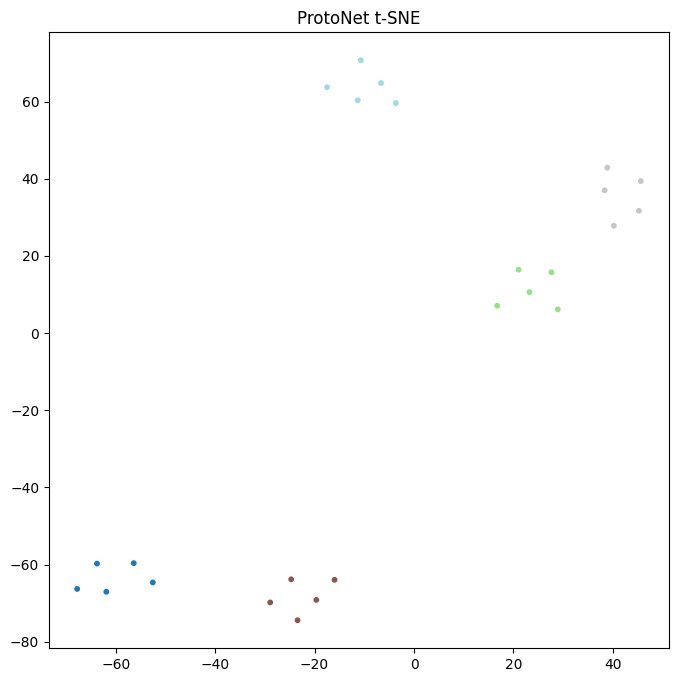

In [42]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

embeddings = []
labels = []

encoder.eval()

with torch.no_grad():
    for i, (support, support_labels, query, query_labels) in enumerate(test_loader):
        if i >= 1:
            break

        query = query.to(device)

        embed = encoder(query)

        embeddings.append(embed.cpu())
        labels.append(query_labels)

embeddings = torch.cat(embeddings)
labels = torch.cat(labels)

tsne = TSNE(n_components=2, perplexity=5)
embeddings_2d = tsne.fit_transform(embeddings.numpy())

plt.figure(figsize=(8,8))
plt.scatter(embeddings_2d[:,0], embeddings_2d[:,1], c=labels, cmap="tab20", s=10)
plt.title("ProtoNet t-SNE")
plt.savefig(model_root + "t-sne.png")
plt.savefig(model_root + "t-sne.svg")
plt.show()

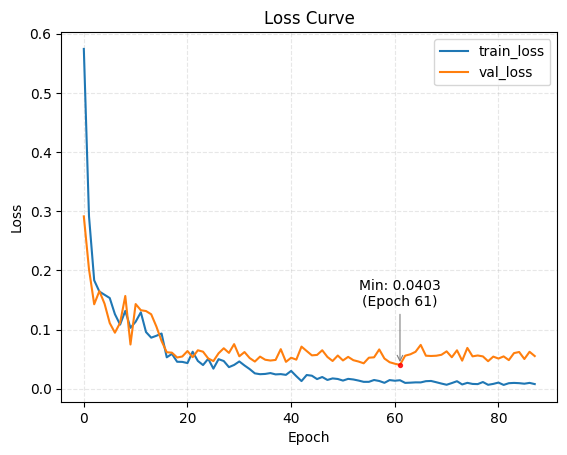

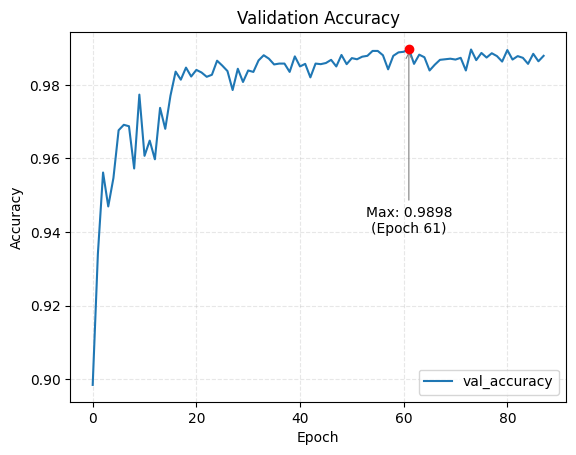

In [43]:
import matplotlib.pyplot as plt

epochs = [log["epoch"] for log in train_logs]
train_loss = [log["train_loss"] for log in train_logs]
val_loss = [log["val_loss"] for log in train_logs]
val_acc = [log["val_accuracy"] for log in train_logs]

# 找最低的 Val Loss
min_loss_val = min(val_loss)
min_loss_idx = val_loss.index(min_loss_val)
min_loss_epoch = epochs[min_loss_idx]

# 找最高的 Val Accuracy
max_acc_val = max(val_acc)
max_acc_idx = val_acc.index(max_acc_val)
max_acc_epoch = epochs[max_acc_idx]

plt.figure()
plt.plot(epochs, train_loss, label="train_loss")

plt.plot(epochs, val_loss, label="val_loss")

plt.scatter(
    min_loss_epoch, min_loss_val, color="red", zorder=5, s=8, alpha=0.8
)  # 红点
plt.annotate(
    f"Min: {min_loss_val:.4f}\n(Epoch {min_loss_epoch})",
    xy=(min_loss_epoch, min_loss_val),  # 箭头指向的目标坐标
    xytext=(
        min_loss_epoch,
        min_loss_val + 0.1,
    ),  # 文字放置的坐标
    arrowprops=dict(arrowstyle="->", color="gray", lw=0.8),
    horizontalalignment="center",
)  # 文字居中对齐

plt.grid(alpha=0.3, linestyle="--")
plt.legend()
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.savefig(model_root + "loss_curve.png")
plt.savefig(model_root + "loss_curve.svg")

plt.figure()
plt.plot(epochs, val_acc, label="val_accuracy")

plt.scatter(max_acc_epoch, max_acc_val, color="red", zorder=5)  # 画个红点
plt.annotate(
    f"Max: {max_acc_val:.4f}\n(Epoch {max_acc_epoch})",
    xy=(max_acc_epoch, max_acc_val),  # 箭头指向的目标坐标
    xytext=(
        max_acc_epoch,
        max_acc_val - 0.05,
    ),  # 文字放置的坐标
    arrowprops=dict(arrowstyle="->", color="gray", lw=0.8),
    horizontalalignment="center",
)

plt.grid(alpha=0.3, linestyle="--")
plt.legend()
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.savefig(model_root + "accuracy_curve.png")
plt.savefig(model_root + "accuracy_curve.svg")
plt.show()

## 导出模型为独立 ATen 图文件

In [44]:
# 分别导出特征提取器 (Encoder) 和 原型网络逻辑 (ProtoNet)

import torch
from torch.export import export, save, Dim

# 从已有 test_loader 获取真实数据
for support, support_labels, query, query_labels in test_loader:
    support = support.cpu()
    support_labels = support_labels.cpu()
    query = query.cpu()
    break

# 为 Encoder 准备示例输入
example_img = support[0:4]

# 确保在 eval 模式并且不计算梯度
encoder.cpu().eval()
proto_net.cpu().eval()

with torch.no_grad():
    # 使用训练好的 encoder 获取真实的 embedding
    embed_support = encoder(support)
    embed_query = encoder(query)

# 定义动态维度 (让模型适应不同的 Way/Shot/Query 数量)
s = Dim.AUTO
q = Dim.AUTO

# 导出 Encoder，允许 batch_size 动态变化
exported_encoder = export(
    encoder, 
    args=(example_img,), 
    dynamic_shapes={"x": {0: Dim.AUTO}}
)
save(exported_encoder, model_root + "encoder.pt2")

# 导出 ProtoNet，传入真实的特征、真实的标签，并标记维度为动态
exported_proto = export(
    proto_net,
    args=(embed_support, support_labels, embed_query),
    dynamic_shapes={
        "embed_support": {0: s},
        "support_labels": {0: s},
        "embed_query": {0: q}
    }
)
save(exported_proto, model_root + "protonet-classifier.pt2")

In [45]:
meta_json['files'] = {
    "models": {
        "encoder": "encoder.pt2",
        "classifier": "protonet-classifier.pt2"
    },
    "images": {
        "loss_curve": "loss_curve.png",
        "loss_curve_svg": "loss_curve.svg",

        "accuracy_curve": "accuracy_curve.png",
        "accuracy_curve_svg": "accuracy_curve.svg",

        "t_sne": "t-sne.png",
        "t_sne_svg": "t-sne.svg"
    }
}

In [46]:
with open(model_root + 'meta.json', 'w') as file:
    json.dump(meta_json, file, indent=2)